In [1]:
import sys
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

In [2]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

Done!


In [3]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [4]:
utc_columns = [
    'timestamp_utc',
    'timestamp_london',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )

In [9]:
demand_data['timestamp_london'] = demand_data['timestamp_utc'].dt.tz_convert('Europe/London')

In [10]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [22]:
train_set = demand_data.loc[demand_data['data_split'] == 'train'].copy()
train_set = train_set.sort_values(by='timestamp_utc').reindex(drop=True)

TypeError: DataFrame.reindex() got an unexpected keyword argument 'drop'

In [23]:
train_set.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaT,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [24]:
train_set.shape

(20400, 33)

In [25]:
train_set['timestamp_utc'].iloc[0], train_set['timestamp_utc'].iloc[-1]

(Timestamp('2023-01-01 00:00:00+0000', tz='UTC'),
 Timestamp('2024-02-29 23:30:00+0000', tz='UTC'))

In [26]:
# checking missing values
train_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 20400 entries, 0 to 20399
Data columns (total 33 columns):
 #   Column                                  Non-Null Count  Dtype                        
---  ------                                  --------------  -----                        
 0   timestamp_utc                           20400 non-null  datetime64[us, UTC]          
 1   interval_end_utc                        20400 non-null  datetime64[us, UTC]          
 2   timestamp_london                        20400 non-null  datetime64[us, Europe/London]
 3   settlement_date                         20400 non-null  datetime64[us]               
 4   settlement_period                       20400 non-null  int64                        
 5   demand_mw                               20400 non-null  int64                        
 6   neso_day_ahead_forecast_mw              20400 non-null  int64                        
 7   historic_nd_mw                          20400 non-null  int64                 

In [27]:
# checking duplicates
(
    train_set['timestamp_utc']
    .diff()
    .dropna()
    .value_counts()
)

timestamp_utc
0 days 00:30:00    20399
Name: count, dtype: int64

#### First Lag

In [28]:
train_set['demand_lag_1'] = train_set['demand_mw'].shift(1)
train_set[['timestamp_utc', 'demand_mw', 'demand_lag_1']].head()

,timestamp_utc,demand_mw,demand_lag_1
0,2023-01-01 00:00:00+00:00,20967,NaN
1,2023-01-01 00:30:00+00:00,21699,20967.0
2,2023-01-01 01:00:00+00:00,21185,21699.0
3,2023-01-01 01:30:00+00:00,20442,21185.0
4,2023-01-01 02:00:00+00:00,19633,20442.0


In [29]:
lag_pairs = train_set.dropna(
    subset=['demand_mw', 'demand_lag_1']
)

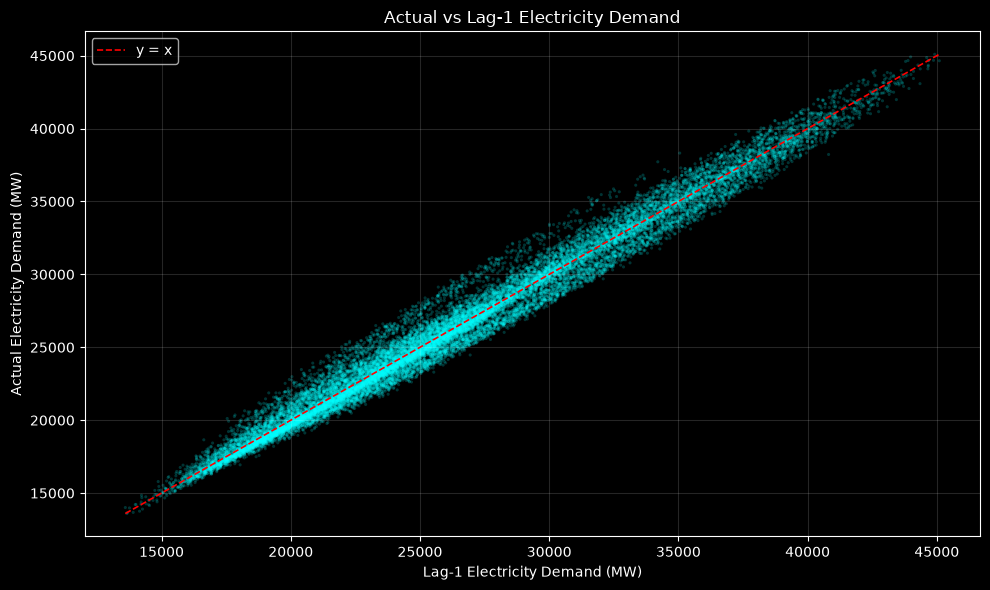

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_1'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_1'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_1'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-1 Electricity Demand',
    xlabel='Lag-1 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [41]:
lag_pairs['demand_mw'].corr(lag_pairs['demand_lag_1']).item()

0.9892280000957202

In [47]:
train_set['demand_lag_48'] = train_set['demand_mw'].shift(48)
train_set['demand_lag_336'] = train_set['demand_mw'].shift(336)

In [43]:
lag_pairs = (
    train_set.dropna(
        subset=['demand_mw', 'demand_lag_48']
    )[['demand_mw', 'demand_lag_48']]
)

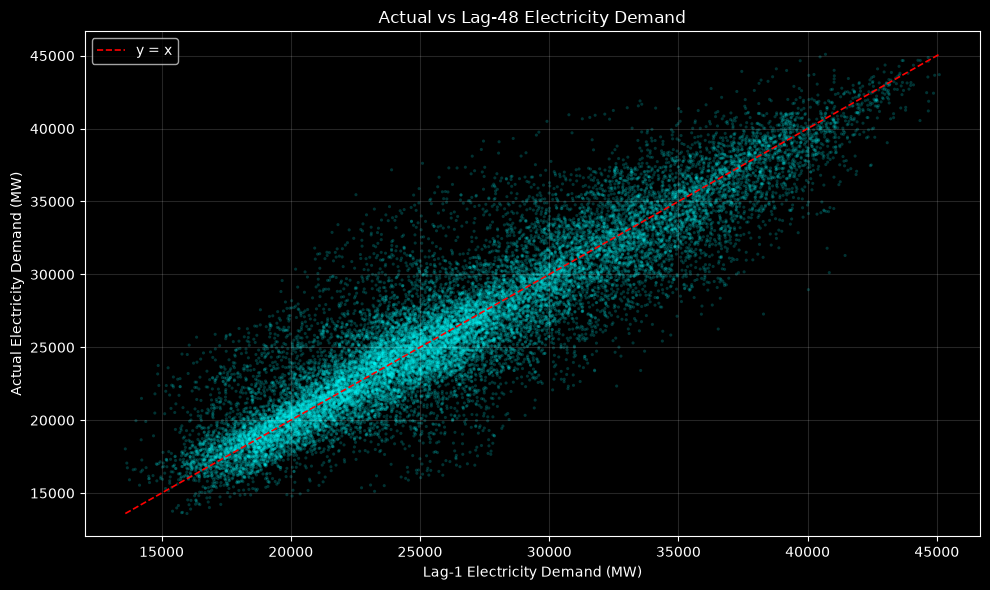

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_48'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_48'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_48'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-48 Electricity Demand',
    xlabel='Lag-1 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [48]:
lag_pairs = (
    train_set.dropna(
        subset=['demand_mw', 'demand_lag_336']
    )[['demand_mw', 'demand_lag_336']]
)

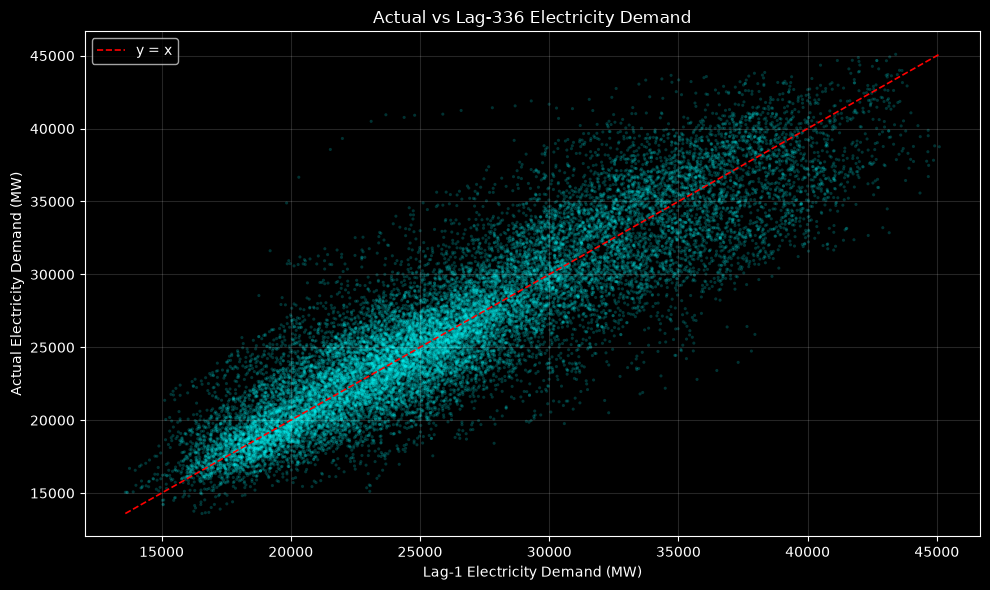

In [49]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    lag_pairs['demand_lag_336'],
    lag_pairs['demand_mw'],
    s=5,
    alpha=0.2,
    color='cyan',
    edgecolors='none'
)

# y = x reference line
min_val = min(lag_pairs['demand_lag_336'].min(), lag_pairs['demand_mw'].min())
max_val = max(lag_pairs['demand_lag_336'].max(), lag_pairs['demand_mw'].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='y = x'
)

ax.set(
    title='Actual vs Lag-336 Electricity Demand',
    xlabel='Lag-1 Electricity Demand (MW)',
    ylabel='Actual Electricity Demand (MW)'
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [53]:
train_set['demand_mw'].corr(train_set['demand_lag_48']).item()

0.9142431502218531

In [54]:
train_set['demand_mw'].corr(train_set['demand_lag_336']).item()

0.892606113495373